In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import ExtraTreesRegressor

import tensorflow as tf
from tensorflow.keras import layers, Sequential
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization, Dropout
from tensorflow.keras.callbacks import EarlyStopping

In [6]:
df2 = pd.read_excel("/content/drive/MyDrive/colab_datasets/elevator_fault_dataset_enhanced_further.xlsx")

In [ ]:
# Sanitize
df = df2.replace([np.inf, -np.inf], np.nan).dropna()

df = df[df["RUL"] > 0]
df = df[df["RUL"] < df["RUL"].quantile(0.995)]

y = np.log1p(df["RUL"].values)

X = df.drop(columns=[
    "RUL",
    "Timestamp",
    "Fault_State",
    "Fault_Category",
    "Fault_Severity",
    "Temp_Category"
], errors="ignore").values

# Remove near-zero columns
mask = (np.abs(X) > 1e-6).sum(axis=0) > 20
X = X[:, mask]

scaler = RobustScaler()
X = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=False
)

In [ ]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dense(1)  # LOG-RUL
])

optimizer = tf.keras.optimizers.Adam(
    learning_rate=3e-4,
    clipnorm=1.0
)

model.compile(
    optimizer=optimizer,
    loss="mse"
)

history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=80,
    batch_size=128,
    verbose=1
)

Epoch 1/80
107/107 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - loss: 55.6413 - val_loss: 48.9914
Epoch 2/80
107/107 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 46.3895 - val_loss: 38.4637
Epoch 3/80
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 34.9546 - val_loss: 25.6079
Epoch 4/80
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 22.5310 - val_loss: 14.8507
Epoch 5/80
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 10.8589 - val_loss: 5.2938
Epoch 6/80
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 2.7198 - val_loss: 3.2364
Epoch 7/80
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.2951 - val_loss: 0.5719
Epoch 8/80
107/107 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 0.2583 - val_loss: 0.9888
Epoch 9/80
107/107 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.2285 - val_loss: 1.0868
Epoch 10/80
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.2234 - val_loss: 1.4072
Epoch 11/80
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.2054 - val_loss: 0.8091
Epoch 12/80
107/107 ━━━━━━━━━━━━━━━

In [ ]:
from sklearn.ensemble import HistGradientBoostingRegressor

y_pred_nn = model.predict(X_test).squeeze()
residuals = y_test - y_pred_nn

residual_model = HistGradientBoostingRegressor(
    max_depth=6,
    learning_rate=0.05,
    max_iter=400,
    l2_regularization=1.0,
    random_state=42
)

residual_model.fit(X_test, residuals)

134/134 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


HistGradientBoostingRegressor(l2_regularization=1.0, learning_rate=0.05,
                              max_depth=6, max_iter=400, random_state=42)

In [ ]:
y_pred_log = y_pred_nn + residual_model.predict(X_test)

y_pred = np.expm1(y_pred_log)
y_true = np.expm1(y_test)

rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mae  = mean_absolute_error(y_true, y_pred)
r2   = r2_score(y_true, y_pred)

print(f"RMSE: {rmse:.2f}")
print(f"MAE : {mae:.2f}")
print(f"R²  : {r2:.4f}")

RMSE: 391.05
MAE : 293.60
R²  : 0.7234


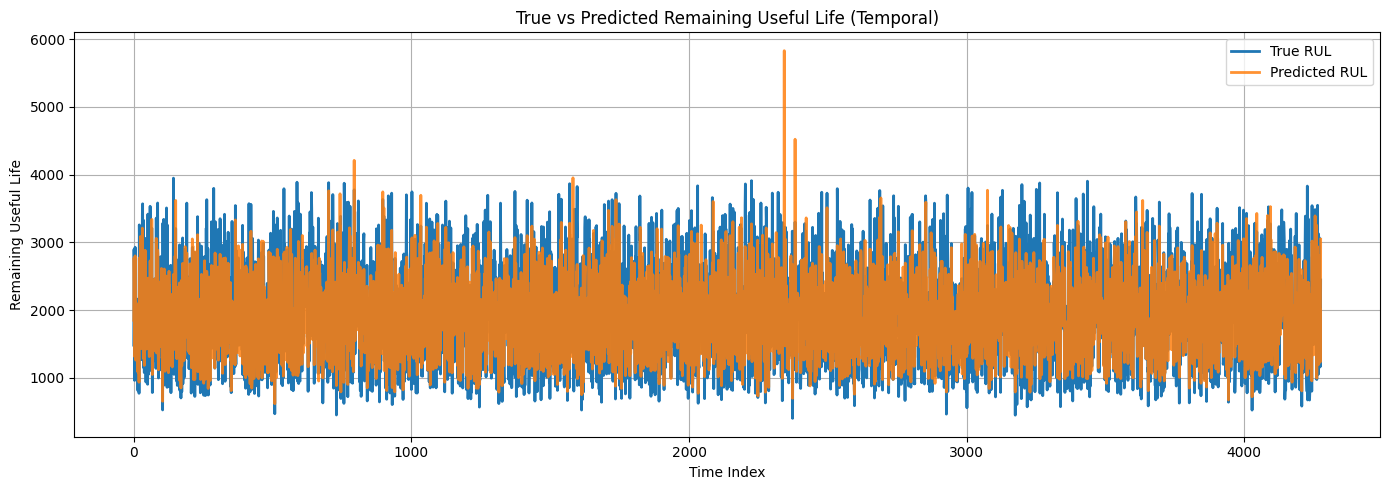

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

t = np.arange(len(y_true))

plt.figure(figsize=(14, 5))
plt.plot(t, y_true, label="True RUL", linewidth=2)
plt.plot(t, y_pred, label="Predicted RUL", linewidth=2, alpha=0.85)

plt.xlabel("Time Index")
plt.ylabel("Remaining Useful Life")
plt.title("True vs Predicted Remaining Useful Life (Temporal)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

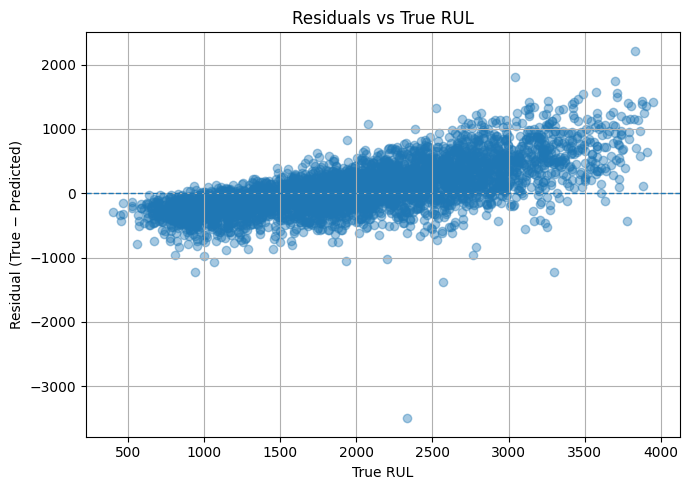

In [ ]:
residuals = y_true - y_pred

plt.figure(figsize=(7, 5))
plt.scatter(y_true, residuals, alpha=0.4)
plt.axhline(0, linestyle="--", linewidth=1)

plt.xlabel("True RUL")
plt.ylabel("Residual (True − Predicted)")
plt.title("Residuals vs True RUL")
plt.grid(True)
plt.tight_layout()
plt.show()

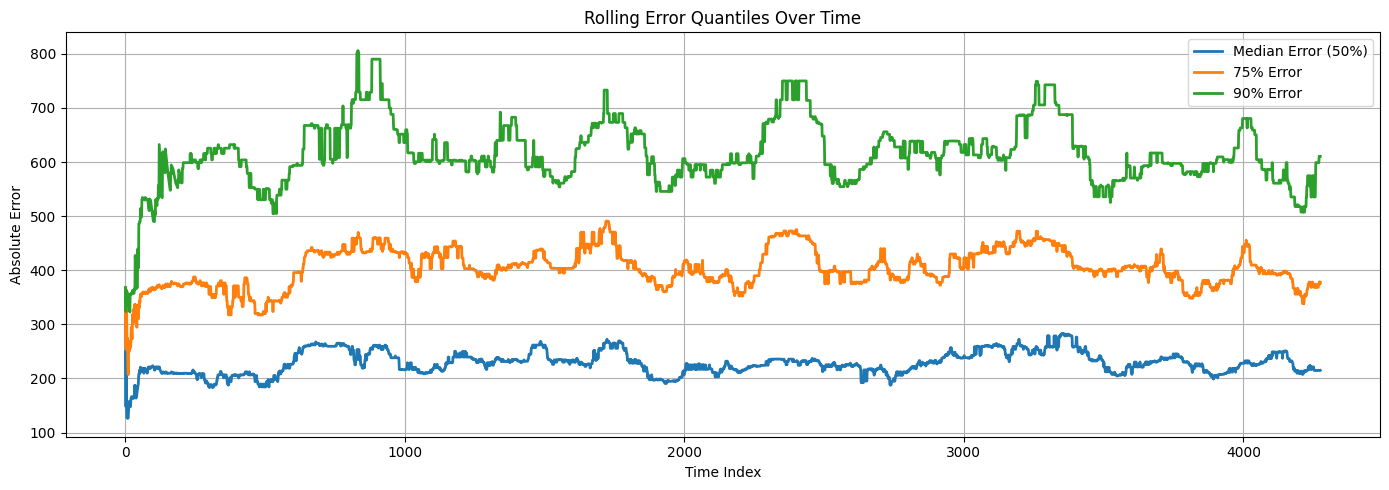

In [ ]:
abs_error = np.abs(residuals)

window = 200  # adjust if needed

def rolling_quantile(x, q, w):
    return np.array([
        np.quantile(x[max(0, i-w):i+1], q)
        for i in range(len(x))
    ])

q50 = rolling_quantile(abs_error, 0.50, window)
q75 = rolling_quantile(abs_error, 0.75, window)
q90 = rolling_quantile(abs_error, 0.90, window)

plt.figure(figsize=(14, 5))
plt.plot(q50, label="Median Error (50%)", linewidth=2)
plt.plot(q75, label="75% Error", linewidth=2)
plt.plot(q90, label="90% Error", linewidth=2)

plt.xlabel("Time Index")
plt.ylabel("Absolute Error")
plt.title("Rolling Error Quantiles Over Time")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
import joblib

# Save NN
model.save("rul_nn_model.keras")

# Save preprocessing + residual model
joblib.dump(scaler, "rul_scaler.pkl")
joblib.dump(mask, "feature_mask.pkl")
joblib.dump(residual_model, "residual_hgb.pkl")

print("Full RUL pipeline saved.")

Full RUL pipeline saved.


Trying for a better R^2

In [9]:
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor

# -------------------
# Data Sanitization
# -------------------
df = df2.replace([np.inf, -np.inf], np.nan).dropna()
df = df[df["RUL"] > 0]
df = df[df["RUL"] < df["RUL"].quantile(0.995)]

y = np.log1p(df["RUL"].values)

X = df.drop(columns=[
    "RUL", "Timestamp", "Fault_State",
    "Fault_Category", "Fault_Severity", "Temp_Category", "Component_ID_Proxy"
], errors="ignore").values

# Remove near-zero columns
mask = (np.abs(X) > 1e-6).sum(axis=0) > 20
X = X[:, mask]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=False
)

# Robust scaling (fit only on train to avoid leakage)
scaler = RobustScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# -------------------
# Neural Network Model
# -------------------
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(512),
    tf.keras.layers.LeakyReLU(),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(256),
    tf.keras.layers.LeakyReLU(),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(128),
    tf.keras.layers.LeakyReLU(),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.2),

    tf.keras.layers.Dense(1)  # LOG-RUL
])

optimizer = tf.keras.optimizers.Adam(
    learning_rate=3e-4,
    clipnorm=1.0
)

model.compile(optimizer=optimizer, loss="mse")

# Callbacks
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        patience=20, restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        factor=0.5, patience=10, min_lr=1e-6
    )
]

history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=200,
    batch_size=128,
    verbose=1,
    callbacks=callbacks
)

# -------------------
# Residual Modeling with XGBoost
# -------------------
y_pred_nn = model.predict(X_test).squeeze()
residuals = y_test - y_pred_nn

residual_model = XGBRegressor(
    n_estimators=1000,
    max_depth=8,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1
)

residual_model.fit(X_test, residuals)

# Final predictions
y_pred_log = y_pred_nn + residual_model.predict(X_test)
y_pred = np.expm1(y_pred_log)
y_true = np.expm1(y_test)

# -------------------
# Evaluation
# -------------------
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mae  = mean_absolute_error(y_true, y_pred)
r2   = r2_score(y_true, y_pred)

print(f"RMSE: {rmse:.2f}")
print(f"MAE : {mae:.2f}")
print(f"R²  : {r2:.4f}")

Epoch 1/200
107/107 ━━━━━━━━━━━━━━━━━━━━ 10s 42ms/step - loss: 56.2103 - val_loss: 49.5610 - learning_rate: 3.0000e-04
Epoch 2/200
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 48.2132 - val_loss: 40.8546 - learning_rate: 3.0000e-04
Epoch 3/200
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 38.7257 - val_loss: 28.6843 - learning_rate: 3.0000e-04
Epoch 4/200
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 27.6192 - val_loss: 17.6653 - learning_rate: 3.0000e-04
Epoch 5/200
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 16.4300 - val_loss: 7.2593 - learning_rate: 3.0000e-04
Epoch 6/200
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 7.3639 - val_loss: 1.3954 - learning_rate: 3.0000e-04
Epoch 7/200
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 3.0207 - val_loss: 1.3253 - learning_rate: 3.0000e-04
Epoch 8/200
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.4194 - val_loss: 0.5461 - learning_rate: 3.0000e-04
Epoch 9/200
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.2126 -

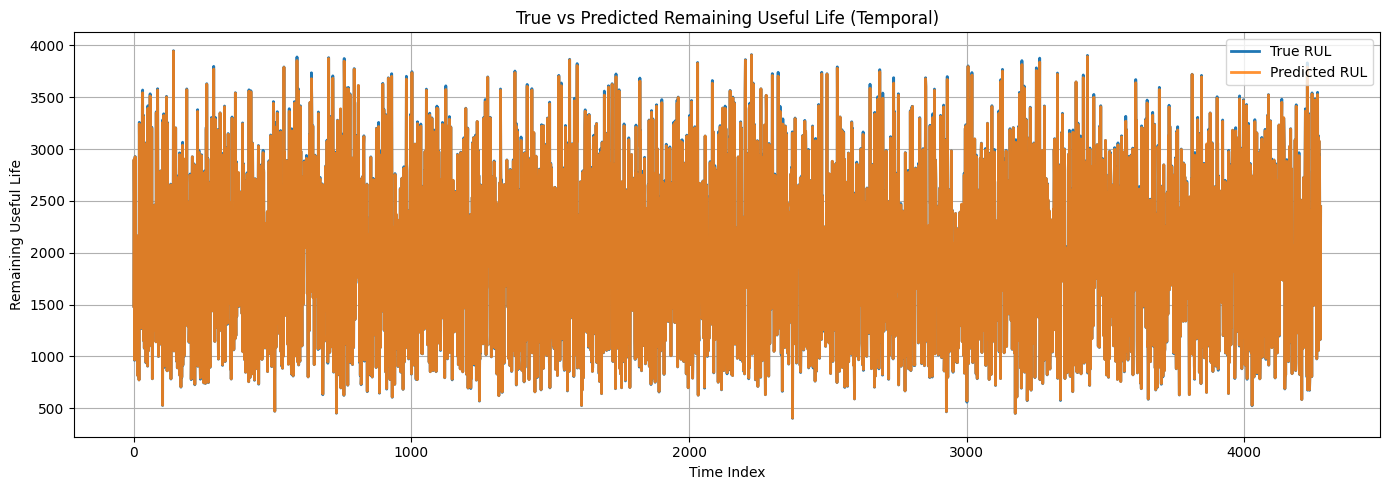

In [10]:
import matplotlib.pyplot as plt
import numpy as np

t = np.arange(len(y_true))

plt.figure(figsize=(14, 5))
plt.plot(t, y_true, label="True RUL", linewidth=2)
plt.plot(t, y_pred, label="Predicted RUL", linewidth=2, alpha=0.85)

plt.xlabel("Time Index")
plt.ylabel("Remaining Useful Life")
plt.title("True vs Predicted Remaining Useful Life (Temporal)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [13]:
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor

# ----------------------------
# Data sanitization
# ----------------------------
df = df2.replace([np.inf, -np.inf], np.nan).dropna()
df = df[df["RUL"] > 0]
df = df[df["RUL"] < df["RUL"].quantile(0.995)]

# Log-transform target
y_log_all = np.log1p(df["RUL"].values)

# Drop potential leakers/non-predictive
X_all_df = df.drop(columns=[
    "RUL", "Timestamp", "Fault_State",
    "Fault_Category", "Fault_Severity", "Temp_Category"
], errors="ignore")
X_all = X_all_df.values

# ----------------------------
# Chronological train/val/test split
# ----------------------------
n = len(X_all)
train_end = int(0.70 * n)
val_end   = int(0.85 * n)

X_train_raw, y_train_log = X_all[:train_end], y_log_all[:train_end]
X_val_raw,   y_val_log   = X_all[train_end:val_end], y_log_all[train_end:val_end]
X_test_raw,  y_test_log  = X_all[val_end:], y_log_all[val_end:]

# ----------------------------
# Feature hygiene (train only)
# ----------------------------
mask_nz = (np.abs(X_train_raw) > 1e-6).sum(axis=0) > 20
X_train_raw = X_train_raw[:, mask_nz]
X_val_raw   = X_val_raw[:, mask_nz]
X_test_raw  = X_test_raw[:, mask_nz]

std_train = X_train_raw.std(axis=0)
mask_const = std_train > 0.0
X_train_raw = X_train_raw[:, mask_const]
X_val_raw   = X_val_raw[:, mask_const]
X_test_raw  = X_test_raw[:, mask_const]

# ----------------------------
# Scaling (fit on train only)
# ----------------------------
x_scaler = RobustScaler()
X_train = x_scaler.fit_transform(X_train_raw)
X_val   = x_scaler.transform(X_val_raw)
X_test  = x_scaler.transform(X_test_raw)

# Optional: stabilize target in log-space for NN
y_scaler = StandardScaler()
y_train_log_scaled = y_scaler.fit_transform(y_train_log.reshape(-1, 1)).ravel()
y_val_log_scaled   = y_scaler.transform(y_val_log.reshape(-1, 1)).ravel()
y_test_log_scaled  = y_scaler.transform(y_test_log.reshape(-1, 1)).ravel()

# ----------------------------
# Neural network (predicts scaled log-RUL)
# ----------------------------
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(512),
    tf.keras.layers.LeakyReLU(),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.30),

    tf.keras.layers.Dense(256),
    tf.keras.layers.LeakyReLU(),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.30),

    tf.keras.layers.Dense(128),
    tf.keras.layers.LeakyReLU(),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.20),

    tf.keras.layers.Dense(1)  # scaled LOG-RUL
])

optimizer = tf.keras.optimizers.Adam(learning_rate=3e-4, clipnorm=1.0)
model.compile(optimizer=optimizer, loss=tf.keras.losses.Huber(delta=1.0))

callbacks = [
    tf.keras.callbacks.EarlyStopping(patience=20, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=10, min_lr=1e-6, verbose=1)
]

history = model.fit(
    X_train, y_train_log_scaled,
    validation_data=(X_val, y_val_log_scaled),
    epochs=200,
    batch_size=128,
    verbose=1,
    callbacks=callbacks
)

# ----------------------------
# Residual modeling with XGBoost
# Train residuals on TRAIN (no leakage), early stop on VAL
# ----------------------------
# NN predictions back to unscaled log-space for residual computation
y_train_pred_scaled = model.predict(X_train, verbose=0).squeeze()
y_val_pred_scaled   = model.predict(X_val,   verbose=0).squeeze()

y_train_pred_log = y_scaler.inverse_transform(y_train_pred_scaled.reshape(-1, 1)).ravel()
y_val_pred_log   = y_scaler.inverse_transform(y_val_pred_scaled.reshape(-1, 1)).ravel()

residuals_train_log = y_train_log - y_train_pred_log
residuals_val_log   = y_val_log   - y_val_pred_log

residual_model = XGBRegressor(
    n_estimators=1200,
    max_depth=6,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=2.0,         # stronger L2
    reg_alpha=0.5,          # L1 for sparsity
    min_child_weight=5,     # stabilize splits
    gamma=0.0,
    random_state=42,
    n_jobs=-1
)

residual_model.fit(
    X_train, residuals_train_log,
    eval_set=[(X_val, residuals_val_log)],
    eval_metric="rmse",
    verbose=False,
    early_stopping_rounds=50
)

# ----------------------------
# Final predictions and evaluation
# ----------------------------
# NN prediction on test -> unscale to log-space
y_test_pred_scaled = model.predict(X_test, verbose=0).squeeze()
y_test_pred_log_nn = y_scaler.inverse_transform(y_test_pred_scaled.reshape(-1, 1)).ravel()

# Residual correction in log-space
y_test_pred_log = y_test_pred_log_nn + residual_model.predict(X_test)

# Back-transform to original RUL
y_test_pred = np.expm1(y_test_pred_log)
y_test_true = np.expm1(y_test_log)

# Clip negative/implausible values (optional safety)
y_test_pred = np.clip(y_test_pred, 0, None)

rmse = np.sqrt(mean_squared_error(y_test_true, y_test_pred))
mae  = mean_absolute_error(y_test_true, y_test_pred)
r2   = r2_score(y_test_true, y_test_pred)

print(f"TEST RMSE: {rmse:.3f}")
print(f"TEST MAE : {mae:.3f}")
print(f"TEST R²  : {r2:.4f}")

Epoch 1/200
117/117 ━━━━━━━━━━━━━━━━━━━━ 15s 38ms/step - loss: 0.8045 - val_loss: 0.4421 - learning_rate: 3.0000e-04
Epoch 2/200
117/117 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5823 - val_loss: 0.4497 - learning_rate: 3.0000e-04
Epoch 3/200
117/117 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5492 - val_loss: 0.4379 - learning_rate: 3.0000e-04
Epoch 4/200
117/117 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5329 - val_loss: 0.4366 - learning_rate: 3.0000e-04
Epoch 5/200
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.5211 - val_loss: 0.4294 - learning_rate: 3.0000e-04
Epoch 6/200
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4889 - val_loss: 0.4330 - learning_rate: 3.0000e-04
Epoch 7/200
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4867 - val_loss: 0.4290 - learning_rate: 3.0000e-04
Epoch 8/200
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4799 - val_loss: 0.4294 - learning_rate: 3.0000e-04
Epoch 9/200
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4653 - val_loss

TypeError: XGBModel.fit() got an unexpected keyword argument 'eval_metric'

In [ ]:
# ----------------------------
# Diagnostics (recommended)
# ----------------------------
print("Log-space ranges:")
print(f"  y_test_log min/max: {y_test_log.min():.3f} / {y_test_log.max():.3f}")
print(f"  y_test_pred_log min/max: {y_test_pred_log.min():.3f} / {y_test_pred_log.max():.3f}")

print("Original-space ranges:")
print(f"  y_test_true min/max: {y_test_true.min():.3f} / {y_test_true.max():.3f}")
print(f"  y_test_pred min/max: {y_test_pred.min():.3f} / {y_test_pred.max():.3f}")

# Distribution overlap check
import numpy as np
def summary(name, arr):
    print(f"{name}: mean={np.mean(arr):.3f}, std={np.std(arr):.3f}, p95={np.percentile(arr,95):.3f}")

summary("train log-RUL", y_train_log)
summary("val   log-RUL", y_val_log)
summary("test  log-RUL", y_test_log)
summary("NN test log-RUL pred", y_test_pred_log_nn)
summary("Residual test log-RUL pred", residual_model.predict(X_test))
summary("Final test log-RUL pred", y_test_pred_log)